In [1]:
# ============================================================
# Locate project root before importing project modules
# ============================================================

from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "data").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:")
print(PROJECT_ROOT)

Project root:
c:\Users\asus\OneDrive\Desktop\siamese-network


In [2]:
# ============================================================
# 512x512 FSL evaluation
# ============================================================

import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score
from pathlib import Path

from src.models import Siamese2D
from src.fsl import (
    create_episode,
    compute_prototypes,
    classify_queries,
)
from src.image_fsl import get_image_embeddings


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CLASS_NAMES = ["normal", "irf", "orf"]

N_EPISODES = 100
QUERY_PER_CLASS = 5

IMAGE_ROOT_512 = (
    PROJECT_ROOT
    / "datasets"
    / "images_512"
)

MODEL_DIR = PROJECT_ROOT / "models"

PREDICTION_DIR = (
    PROJECT_ROOT
    / "results"
    / "predictions"
)

PREDICTION_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Load split
# ------------------------------------------------------------

split = np.load(
    PROJECT_ROOT
    / "results"
    / "fsl_split.npz"
)

test_idx = split["test_idx"]
y = split["y"]

print("Test samples:", len(test_idx))


# ------------------------------------------------------------
# Load model
# ------------------------------------------------------------

def load_model(checkpoint_name):

    model = Siamese2D(
        embedding_dim=128
    ).to(DEVICE)

    checkpoint = torch.load(
        MODEL_DIR / checkpoint_name,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    return model


gasf_model = load_model(
    "fsl_gasf_512_best.pt"
)

gadf_model = load_model(
    "fsl_gadf_512_best.pt"
)

print("Both 512 models loaded.")

Test samples: 45
Both 512 models loaded.


In [3]:
# ============================================================
# Few-shot evaluation function
# ============================================================

def distances_to_probabilities(distances):

    logits = -distances

    logits = (
        logits
        - logits.max(
            axis=1,
            keepdims=True
        )
    )

    exp_logits = np.exp(logits)

    return (
        exp_logits
        / exp_logits.sum(
            axis=1,
            keepdims=True
        )
    )


def evaluate_512_model(
    model,
    representation,
    k_shot
):

    all_true = []
    all_pred = []
    all_probabilities = []

    episode_accuracies = []
    episode_f1s = []

    rng = np.random.default_rng(42)

    for episode_number in range(
        N_EPISODES
    ):

        episode = create_episode(
            indices=test_idx,
            labels=y,
            n_way=3,
            k_shot=k_shot,
            query_per_class=QUERY_PER_CLASS,
            rng=rng
        )

        support_embeddings = (
            get_image_embeddings(
                model=model,
                image_root=IMAGE_ROOT_512,
                indices=episode.support_indices,
                labels=y,
                class_names=CLASS_NAMES,
                representation=representation,
                device=DEVICE,
                batch_size=8
            )
        )

        query_embeddings = (
            get_image_embeddings(
                model=model,
                image_root=IMAGE_ROOT_512,
                indices=episode.query_indices,
                labels=y,
                class_names=CLASS_NAMES,
                representation=representation,
                device=DEVICE,
                batch_size=8
            )
        )

        prototypes = compute_prototypes(
            support_embeddings,
            episode.support_labels
        )

        predictions, distances = (
            classify_queries(
                query_embeddings,
                prototypes
            )
        )

        probabilities = (
            distances_to_probabilities(
                distances
            )
        )

        y_true_episode = (
            episode.query_labels
        )

        accuracy = accuracy_score(
            y_true_episode,
            predictions
        )

        f1 = f1_score(
            y_true_episode,
            predictions,
            average="macro"
        )

        episode_accuracies.append(
            accuracy
        )

        episode_f1s.append(f1)

        all_true.extend(
            y_true_episode.tolist()
        )

        all_pred.extend(
            predictions.tolist()
        )

        all_probabilities.append(
            probabilities
        )

    return {
        "y_true": np.asarray(
            all_true,
            dtype=np.int64
        ),

        "y_pred": np.asarray(
            all_pred,
            dtype=np.int64
        ),

        "probabilities": np.concatenate(
            all_probabilities,
            axis=0
        ),

        "episode_accuracy": np.asarray(
            episode_accuracies
        ),

        "episode_f1": np.asarray(
            episode_f1s
        )
    }

In [4]:
# ============================================================
# Run 512x512 FSL experiments
# ============================================================

evaluations_512 = {}

for representation, model in [
    ("gasf", gasf_model),
    ("gadf", gadf_model)
]:

    for k_shot in [1, 5]:

        key = (
            f"{representation}_512_"
            f"{k_shot}shot"
        )

        print(
            f"\nEvaluating "
            f"{representation.upper()} 512 "
            f"— {k_shot}-shot..."
        )

        result = evaluate_512_model(
            model=model,
            representation=representation,
            k_shot=k_shot
        )

        evaluations_512[key] = result

        accuracy = accuracy_score(
            result["y_true"],
            result["y_pred"]
        )

        f1 = f1_score(
            result["y_true"],
            result["y_pred"],
            average="macro"
        )

        print(
            f"Accuracy: {accuracy:.4f}"
        )

        print(
            f"F1:       {f1:.4f}"
        )


Evaluating GASF 512 — 1-shot...
Accuracy: 0.3547
F1:       0.3528

Evaluating GASF 512 — 5-shot...
Accuracy: 0.3353
F1:       0.3314

Evaluating GADF 512 — 1-shot...
Accuracy: 0.5220
F1:       0.5195

Evaluating GADF 512 — 5-shot...
Accuracy: 0.5840
F1:       0.5754


In [5]:
# ============================================================
# Save 512 prediction files
# ============================================================

for key, result in evaluations_512.items():

    path = (
        PREDICTION_DIR
        / f"{key}.npz"
    )

    np.savez(
        path,
        y_true=result["y_true"],
        y_pred=result["y_pred"],
        probabilities=result["probabilities"],
        episode_accuracy=result["episode_accuracy"],
        episode_f1=result["episode_f1"]
    )

    print(
        "Saved:",
        path
    )

Saved: c:\Users\asus\OneDrive\Desktop\siamese-network\results\predictions\gasf_512_1shot.npz
Saved: c:\Users\asus\OneDrive\Desktop\siamese-network\results\predictions\gasf_512_5shot.npz
Saved: c:\Users\asus\OneDrive\Desktop\siamese-network\results\predictions\gadf_512_1shot.npz
Saved: c:\Users\asus\OneDrive\Desktop\siamese-network\results\predictions\gadf_512_5shot.npz


In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "data").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.append(str(PROJECT_ROOT / "src"))

from models import Siamese2D
from fsl import (
    create_episode,
    compute_prototypes,
    classify_queries
)
from image_fsl import get_image_embeddings

print("Imports OK")

Imports OK


In [3]:
# --------------------------------------------------
# Paths
# --------------------------------------------------

PROJECT_ROOT = Path("..")

IMAGE_ROOT = PROJECT_ROOT / "datasets" / "images"
MODEL_ROOT = PROJECT_ROOT / "models"
RESULT_ROOT = PROJECT_ROOT / "results"

FIGURE_ROOT = RESULT_ROOT / "figures" / "fsl_512"

FIGURE_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


# --------------------------------------------------
# Dataset configuration
# --------------------------------------------------

CLASS_NAMES = [
    "normal",
    "irf",
    "orf"
]

CLASS_IDS = [0, 1, 2]

N_WAY = 3
QUERY_PER_CLASS = 5
N_EPISODES = 100

IMAGE_SIZE = 512

REPRESENTATIONS = [
    "gasf",
    "gadf"
]


# --------------------------------------------------
# Device
# --------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Image root:", IMAGE_ROOT)
print("Model root:", MODEL_ROOT)
print("Figure root:", FIGURE_ROOT)

Device: cpu
Image root: ..\datasets\images
Model root: ..\models
Figure root: ..\results\figures\fsl_512


In [4]:
from PIL import Image

for representation in REPRESENTATIONS:

    print(f"\n{representation.upper()}")

    for class_name in CLASS_NAMES:

        folder = (
            IMAGE_ROOT
            / representation
            / class_name
        )

        files = sorted(folder.glob("*.png"))

        print(
            f"{class_name}: {len(files)} images"
        )

        if len(files) > 0:

            with Image.open(files[0]) as img:
                print(
                    "  First image size:",
                    img.size
                )


GASF
normal: 100 images
  First image size: (224, 224)
irf: 100 images
  First image size: (224, 224)
orf: 100 images
  First image size: (224, 224)

GADF
normal: 100 images
  First image size: (224, 224)
irf: 100 images
  First image size: (224, 224)
orf: 100 images
  First image size: (224, 224)


In [5]:
split_path = RESULT_ROOT / "fsl_split.npz"

split = np.load(split_path)

train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]
y = split["y"]

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

print("\nTest distribution:")

for class_id, class_name in enumerate(CLASS_NAMES):

    count = np.sum(
        y[test_idx] == class_id
    )

    print(
        f"{class_name}: {count}"
    )

Train: 210
Validation: 45
Test: 45

Test distribution:
normal: 15
irf: 15
orf: 15


In [6]:
print(
    "Train ∩ Validation:",
    len(set(train_idx) & set(val_idx))
)

print(
    "Train ∩ Test:",
    len(set(train_idx) & set(test_idx))
)

print(
    "Validation ∩ Test:",
    len(set(val_idx) & set(test_idx))
)

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [7]:
gasf_model = Siamese2D(
    embedding_dim=128
).to(device)

gasf_checkpoint_path = (
    MODEL_ROOT / "fsl_gasf_512_best.pt"
)

checkpoint = torch.load(
    gasf_checkpoint_path,
    map_location=device
)

if "model_state_dict" in checkpoint:

    gasf_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

else:

    gasf_model.load_state_dict(
        checkpoint
    )

gasf_model.eval()

print("GASF 512 model loaded.")
print(
    "Checkpoint:",
    gasf_checkpoint_path
)

GASF 512 model loaded.
Checkpoint: ..\models\fsl_gasf_512_best.pt


In [8]:
gadf_model = Siamese2D(
    embedding_dim=128
).to(device)

gadf_checkpoint_path = (
    MODEL_ROOT / "fsl_gadf_512_best.pt"
)

checkpoint = torch.load(
    gadf_checkpoint_path,
    map_location=device
)

if "model_state_dict" in checkpoint:

    gadf_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

else:

    gadf_model.load_state_dict(
        checkpoint
    )

gadf_model.eval()

print("GADF 512 model loaded.")
print(
    "Checkpoint:",
    gadf_checkpoint_path
)

GADF 512 model loaded.
Checkpoint: ..\models\fsl_gadf_512_best.pt


In [9]:
gadf_model = Siamese2D(
    embedding_dim=128
).to(device)

gadf_checkpoint_path = (
    MODEL_ROOT / "fsl_gadf_512_best.pt"
)

checkpoint = torch.load(
    gadf_checkpoint_path,
    map_location=device
)

if "model_state_dict" in checkpoint:

    gadf_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

else:

    gadf_model.load_state_dict(
        checkpoint
    )

gadf_model.eval()

print("GADF 512 model loaded.")
print(
    "Checkpoint:",
    gadf_checkpoint_path
)

GADF 512 model loaded.
Checkpoint: ..\models\fsl_gadf_512_best.pt


In [10]:
from PIL import Image

test_image_path = (
    IMAGE_ROOT
    / "gadf"
    / "normal"
    / "normal_000.png"
)

image = Image.open(
    test_image_path
).convert("L")

print("Image size:", image.size)

image_array = (
    np.asarray(
        image,
        dtype=np.float32
    ) / 255.0
)

image_tensor = (
    torch.from_numpy(image_array)
    .unsqueeze(0)
    .unsqueeze(0)
    .to(device)
)

with torch.no_grad():

    embedding = gadf_model.encoder(
        image_tensor
    )

print(
    "Embedding shape:",
    embedding.shape
)

Image size: (224, 224)
Embedding shape: torch.Size([1, 128])


In [11]:
def evaluate_image_fsl(
    model,
    image_root,
    representation,
    test_idx,
    labels,
    class_names,
    device,
    k_shot,
    n_episodes=100,
    query_per_class=5,
    seed=42
):

    rng = np.random.default_rng(
        seed + k_shot
    )

    all_true = []
    all_pred = []
    all_distances = []

    model.eval()

    for episode_number in range(
        n_episodes
    ):

        episode = create_episode(
            indices=test_idx,
            labels=labels,
            n_way=3,
            k_shot=k_shot,
            query_per_class=query_per_class,
            rng=rng
        )

        # -------------------------------
        # Support embeddings
        # -------------------------------

        support_embeddings = get_image_embeddings(
            model=model,
            image_root=image_root,
            indices=episode.support_indices,
            labels=labels,
            class_names=class_names,
            representation=representation,
            device=device
        )

        # -------------------------------
        # Query embeddings
        # -------------------------------

        query_embeddings = get_image_embeddings(
            model=model,
            image_root=image_root,
            indices=episode.query_indices,
            labels=labels,
            class_names=class_names,
            representation=representation,
            device=device
        )

        # -------------------------------
        # Class prototypes
        # -------------------------------

        prototypes = compute_prototypes(
            support_embeddings,
            episode.support_labels
        )

        # -------------------------------
        # Query classification
        # -------------------------------

        predictions, distances = classify_queries(
            query_embeddings,
            prototypes
        )

        all_true.extend(
            episode.query_labels
        )

        all_pred.extend(
            predictions
        )

        all_distances.extend(
            distances
        )

    all_true = np.asarray(
        all_true
    )

    all_pred = np.asarray(
        all_pred
    )

    all_distances = np.asarray(
        all_distances
    )

    # -------------------------------
    # Accuracy
    # -------------------------------

    accuracy = accuracy_score(
        all_true,
        all_pred
    )

    # -------------------------------
    # Macro F1
    # -------------------------------

    f1 = f1_score(
        all_true,
        all_pred,
        average="macro"
    )

    # -------------------------------
    # Confusion matrix
    # -------------------------------

    cm = confusion_matrix(
        all_true,
        all_pred,
        labels=CLASS_IDS
    )

    return {
        "y_true": all_true,
        "y_pred": all_pred,
        "distances": all_distances,
        "accuracy": accuracy,
        "f1": f1,
        "confusion_matrix": cm
    }

In [12]:
def compute_multiclass_roc(result):

    y_true = result["y_true"]
    distances = result["distances"]

    # One-hot labels
    y_true_bin = label_binarize(
        y_true,
        classes=CLASS_IDS
    )

    # Convert distances to similarity scores
    scores = -distances

    fpr = {}
    tpr = {}
    roc_auc = {}

    for class_id, class_name in enumerate(
        CLASS_NAMES
    ):

        fpr[class_id], tpr[class_id], _ = (
            roc_curve(
                y_true_bin[:, class_id],
                scores[:, class_id]
            )
        )

        roc_auc[class_id] = auc(
            fpr[class_id],
            tpr[class_id]
        )

    # Macro one-vs-rest AUC
    macro_auc = roc_auc_score(
        y_true_bin,
        scores,
        average="macro",
        multi_class="ovr"
    )

    result["fpr"] = fpr
    result["tpr"] = tpr
    result["roc_auc"] = roc_auc
    result["macro_auc"] = macro_auc

    return result

In [13]:
print(
    "Evaluating GASF 512 — 1-shot..."
)

gasf_1shot = evaluate_image_fsl(
    model=gasf_model,
    image_root=IMAGE_ROOT,
    representation="gasf",
    test_idx=test_idx,
    labels=y,
    class_names=CLASS_NAMES,
    device=device,
    k_shot=1,
    n_episodes=N_EPISODES,
    query_per_class=QUERY_PER_CLASS,
    seed=42
)

gasf_1shot = compute_multiclass_roc(
    gasf_1shot
)

print(
    f"Accuracy: {gasf_1shot['accuracy']:.4f}"
)

print(
    f"F1:       {gasf_1shot['f1']:.4f}"
)

print(
    f"Macro AUC: {gasf_1shot['macro_auc']:.4f}"
)

Evaluating GASF 512 — 1-shot...
Accuracy: 0.3360
F1:       0.3075
Macro AUC: 0.5007


In [14]:
print(
    "Evaluating GASF 512 — 5-shot..."
)

gasf_5shot = evaluate_image_fsl(
    model=gasf_model,
    image_root=IMAGE_ROOT,
    representation="gasf",
    test_idx=test_idx,
    labels=y,
    class_names=CLASS_NAMES,
    device=device,
    k_shot=5,
    n_episodes=N_EPISODES,
    query_per_class=QUERY_PER_CLASS,
    seed=42
)

gasf_5shot = compute_multiclass_roc(
    gasf_5shot
)

print(
    f"Accuracy: {gasf_5shot['accuracy']:.4f}"
)

print(
    f"F1:       {gasf_5shot['f1']:.4f}"
)

print(
    f"Macro AUC: {gasf_5shot['macro_auc']:.4f}"
)

Evaluating GASF 512 — 5-shot...
Accuracy: 0.3833
F1:       0.3674
Macro AUC: 0.4835


In [15]:
print(
    "Evaluating GADF 512 — 1-shot..."
)

gadf_1shot = evaluate_image_fsl(
    model=gadf_model,
    image_root=IMAGE_ROOT,
    representation="gadf",
    test_idx=test_idx,
    labels=y,
    class_names=CLASS_NAMES,
    device=device,
    k_shot=1,
    n_episodes=N_EPISODES,
    query_per_class=QUERY_PER_CLASS,
    seed=42
)

gadf_1shot = compute_multiclass_roc(
    gadf_1shot
)

print(
    f"Accuracy: {gadf_1shot['accuracy']:.4f}"
)

print(
    f"F1:       {gadf_1shot['f1']:.4f}"
)

print(
    f"Macro AUC: {gadf_1shot['macro_auc']:.4f}"
)

Evaluating GADF 512 — 1-shot...
Accuracy: 0.5193
F1:       0.5143
Macro AUC: 0.6791


In [16]:
print(
    "Evaluating GADF 512 — 5-shot..."
)

gadf_5shot = evaluate_image_fsl(
    model=gadf_model,
    image_root=IMAGE_ROOT,
    representation="gadf",
    test_idx=test_idx,
    labels=y,
    class_names=CLASS_NAMES,
    device=device,
    k_shot=5,
    n_episodes=N_EPISODES,
    query_per_class=QUERY_PER_CLASS,
    seed=42
)

gadf_5shot = compute_multiclass_roc(
    gadf_5shot
)

print(
    f"Accuracy: {gadf_5shot['accuracy']:.4f}"
)

print(
    f"F1:       {gadf_5shot['f1']:.4f}"
)

print(
    f"Macro AUC: {gadf_5shot['macro_auc']:.4f}"
)

Evaluating GADF 512 — 5-shot...
Accuracy: 0.5613
F1:       0.5607
Macro AUC: 0.7400


In [17]:
final_512_table = pd.DataFrame([
    {
        "Representation": "GASF 512",
        "Shot": "1-shot",
        "Accuracy": gasf_1shot["accuracy"],
        "F1": gasf_1shot["f1"],
        "Macro AUC": gasf_1shot["macro_auc"]
    },
    {
        "Representation": "GASF 512",
        "Shot": "5-shot",
        "Accuracy": gasf_5shot["accuracy"],
        "F1": gasf_5shot["f1"],
        "Macro AUC": gasf_5shot["macro_auc"]
    },
    {
        "Representation": "GADF 512",
        "Shot": "1-shot",
        "Accuracy": gadf_1shot["accuracy"],
        "F1": gadf_1shot["f1"],
        "Macro AUC": gadf_1shot["macro_auc"]
    },
    {
        "Representation": "GADF 512",
        "Shot": "5-shot",
        "Accuracy": gadf_5shot["accuracy"],
        "F1": gadf_5shot["f1"],
        "Macro AUC": gadf_5shot["macro_auc"]
    }
])

final_512_table

,Representation,Shot,Accuracy,F1,Macro AUC
0,GASF 512,1-shot,0.336000,0.307531,0.500722
1,GASF 512,5-shot,0.383333,0.367365,0.483534
2,GADF 512,1-shot,0.519333,0.514309,0.679148
3,GADF 512,5-shot,0.561333,0.560700,0.739985


In [18]:
auc_table = pd.DataFrame([
    {
        "Representation": "GASF 512",
        "Shot": "1-shot",
        "Normal AUC": gasf_1shot["roc_auc"][0],
        "IRF AUC": gasf_1shot["roc_auc"][1],
        "ORF AUC": gasf_1shot["roc_auc"][2],
        "Macro AUC": gasf_1shot["macro_auc"]
    },
    {
        "Representation": "GASF 512",
        "Shot": "5-shot",
        "Normal AUC": gasf_5shot["roc_auc"][0],
        "IRF AUC": gasf_5shot["roc_auc"][1],
        "ORF AUC": gasf_5shot["roc_auc"][2],
        "Macro AUC": gasf_5shot["macro_auc"]
    },
    {
        "Representation": "GADF 512",
        "Shot": "1-shot",
        "Normal AUC": gadf_1shot["roc_auc"][0],
        "IRF AUC": gadf_1shot["roc_auc"][1],
        "ORF AUC": gadf_1shot["roc_auc"][2],
        "Macro AUC": gadf_1shot["macro_auc"]
    },
    {
        "Representation": "GADF 512",
        "Shot": "5-shot",
        "Normal AUC": gadf_5shot["roc_auc"][0],
        "IRF AUC": gadf_5shot["roc_auc"][1],
        "ORF AUC": gadf_5shot["roc_auc"][2],
        "Macro AUC": gadf_5shot["macro_auc"]
    }
])

auc_table

,Representation,Shot,Normal AUC,IRF AUC,ORF AUC,Macro AUC
0,GASF 512,1-shot,0.457171,0.487977,0.557017,0.500722
1,GASF 512,5-shot,0.416813,0.487615,0.546175,0.483534
2,GADF 512,1-shot,0.583402,0.734694,0.719348,0.679148
3,GADF 512,5-shot,0.594202,0.856260,0.769492,0.739985


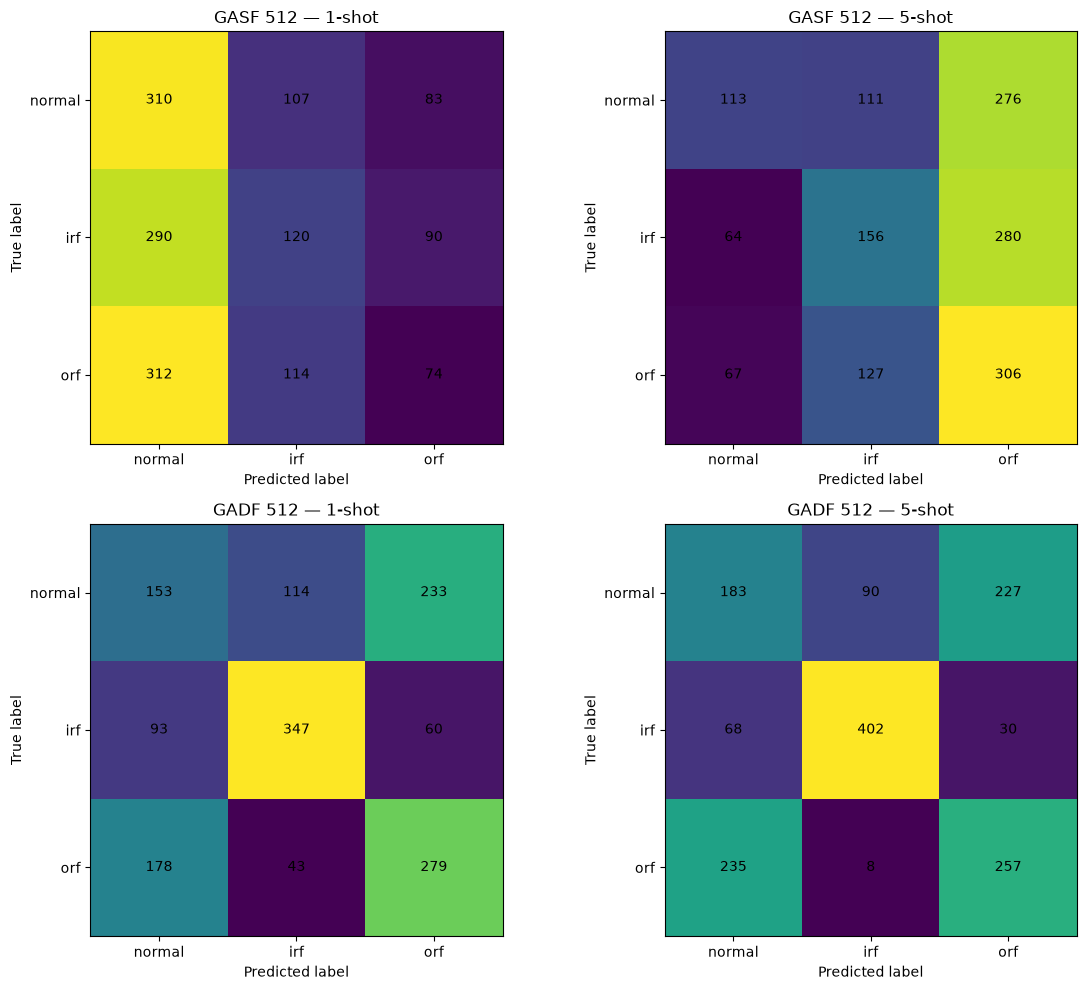

In [19]:
experiments = [
    ("GASF 512 — 1-shot", gasf_1shot),
    ("GASF 512 — 5-shot", gasf_5shot),
    ("GADF 512 — 1-shot", gadf_1shot),
    ("GADF 512 — 5-shot", gadf_5shot)
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10)
)

for ax, (title, result) in zip(
    axes.ravel(),
    experiments
):

    cm = result["confusion_matrix"]

    im = ax.imshow(cm)

    ax.set_title(title)

    ax.set_xlabel(
        "Predicted label"
    )

    ax.set_ylabel(
        "True label"
    )

    ax.set_xticks(
        CLASS_IDS
    )

    ax.set_yticks(
        CLASS_IDS
    )

    ax.set_xticklabels(
        CLASS_NAMES
    )

    ax.set_yticklabels(
        CLASS_NAMES
    )

    for i in range(3):

        for j in range(3):

            ax.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT / "all_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

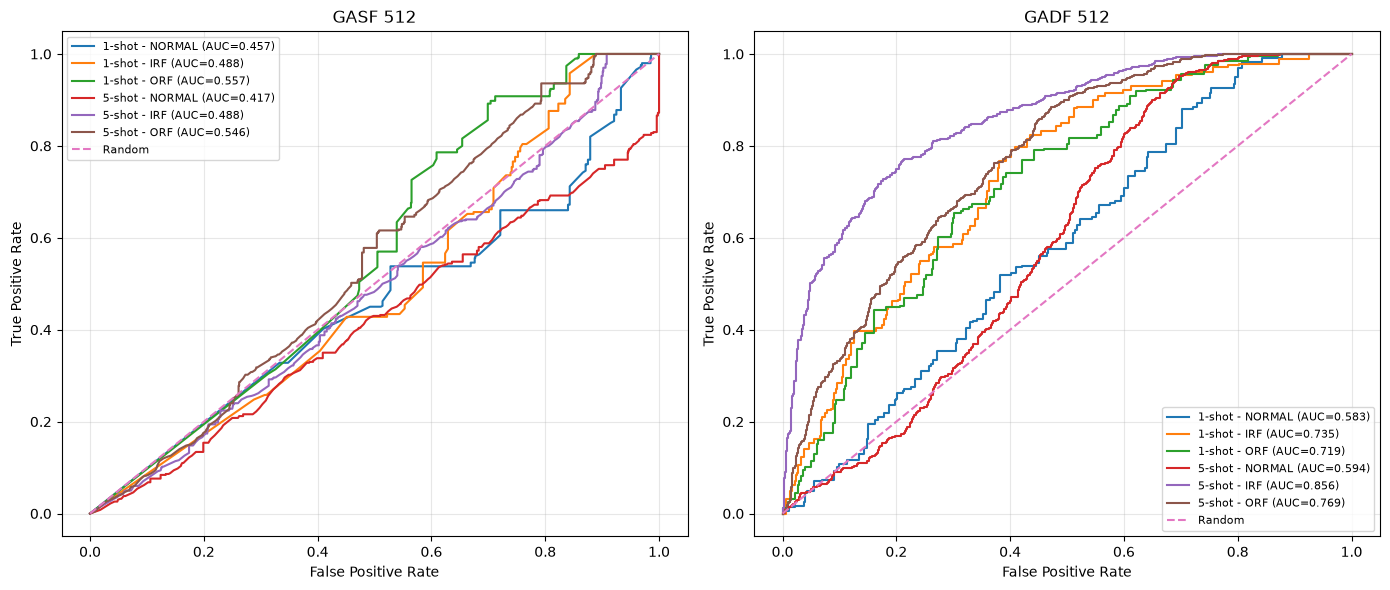

In [20]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)

for ax, representation, results in [
    (
        axes[0],
        "GASF 512",
        [gasf_1shot, gasf_5shot]
    ),
    (
        axes[1],
        "GADF 512",
        [gadf_1shot, gadf_5shot]
    )
]:

    for result, shot in zip(
        results,
        ["1-shot", "5-shot"]
    ):

        for class_id, class_name in enumerate(
            CLASS_NAMES
        ):

            ax.plot(
                result["fpr"][class_id],
                result["tpr"][class_id],
                label=(
                    f"{shot} - "
                    f"{class_name.upper()} "
                    f"(AUC="
                    f"{result['roc_auc'][class_id]:.3f})"
                )
            )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random"
    )

    ax.set_xlabel(
        "False Positive Rate"
    )

    ax.set_ylabel(
        "True Positive Rate"
    )

    ax.set_title(
        representation
    )

    ax.legend(
        fontsize=8
    )

    ax.grid(
        alpha=0.3
    )

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT / "all_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
final_512_table.to_csv(
    RESULT_ROOT / "fsl_512_final_metrics.csv",
    index=False
)

auc_table.to_csv(
    RESULT_ROOT / "fsl_512_auc_by_class.csv",
    index=False
)

print(
    "Saved:"
)

print(
    RESULT_ROOT / "fsl_512_final_metrics.csv"
)

print(
    RESULT_ROOT / "fsl_512_auc_by_class.csv"
)

Saved:
..\results\fsl_512_final_metrics.csv
..\results\fsl_512_auc_by_class.csv


In [22]:
best_row = final_512_table.loc[
    final_512_table["Accuracy"].idxmax()
]

print("=" * 70)
print("FINAL 512×512 FSL EVALUATION")
print("=" * 70)

print(
    final_512_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nBest 512×512 configuration:")
print(
    f"Representation: "
    f"{best_row['Representation']}"
)

print(
    f"Setting: "
    f"{best_row['Shot']}"
)

print(
    f"Accuracy: "
    f"{best_row['Accuracy']:.4f}"
)

print(
    f"F1: "
    f"{best_row['F1']:.4f}"
)

print(
    f"Macro AUC: "
    f"{best_row['Macro AUC']:.4f}"
)

FINAL 512×512 FSL EVALUATION
Representation   Shot  Accuracy     F1  Macro AUC
      GASF 512 1-shot    0.3360 0.3075     0.5007
      GASF 512 5-shot    0.3833 0.3674     0.4835
      GADF 512 1-shot    0.5193 0.5143     0.6791
      GADF 512 5-shot    0.5613 0.5607     0.7400

Best 512×512 configuration:
Representation: GADF 512
Setting: 5-shot
Accuracy: 0.5613
F1: 0.5607
Macro AUC: 0.7400


In [24]:
# ============================================================
# FINAL 512 RUN SUMMARY
# ============================================================

final_512_summary = {
    "GASF_512_1shot": {
        "accuracy": float(gasf_1shot["accuracy"]),
        "f1": float(gasf_1shot["f1"]),
        "macro_auc": float(gasf_1shot["macro_auc"])
    },

    "GASF_512_5shot": {
        "accuracy": float(gasf_5shot["accuracy"]),
        "f1": float(gasf_5shot["f1"]),
        "macro_auc": float(gasf_5shot["macro_auc"])
    },

    "GADF_512_1shot": {
        "accuracy": float(gadf_1shot["accuracy"]),
        "f1": float(gadf_1shot["f1"]),
        "macro_auc": float(gadf_1shot["macro_auc"])
    },

    "GADF_512_5shot": {
        "accuracy": float(gadf_5shot["accuracy"]),
        "f1": float(gadf_5shot["f1"]),
        "macro_auc": float(gadf_5shot["macro_auc"])
    }
}

import json

with open(
    RESULT_ROOT / "fsl_512_final_summary.json",
    "w"
) as f:

    json.dump(
        final_512_summary,
        f,
        indent=4
    )

print("Final 512 results saved.")

Final 512 results saved.
